In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project root
PROJECT_ROOT = Path.cwd()

# If the notebook is launched from the notebooks folder,
# use its parent as the project root.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "cleaned"
    / "telco_churn_cleaned.csv"
)

OUTPUT_PATH = PROJECT_ROOT / "visualizations"

# Load cleaned data
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 7043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

display(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values(
        "Missing_Count",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
TotalCharges,11,0.16


# 4 Analyze overallcustomer churn
### 4.1 calculate key metrics

In [7]:
# Check target values first
print(df["Churn"].value_counts(dropna=False))

# Calculate customer metrics
total_customers = len(df)

churned_customers = df["Churn"].eq("Yes").sum()

retained_customers = df["Churn"].eq("No").sum()

churn_rate = (
    churned_customers / total_customers * 100
    if total_customers else np.nan
)

retention_rate = (
    retained_customers / total_customers * 100
    if total_customers else np.nan
)

print(f"Total Customers: {total_customers:,}")
print(f"Churned Customers: {churned_customers:,}")
print(f"Retained Customers: {retained_customers:,}")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Total Customers: 7,043
Churned Customers: 1,869
Retained Customers: 5,174
Churn Rate: 26.54%
Retention Rate: 73.46%


### 4.2 Visualize churn distribution

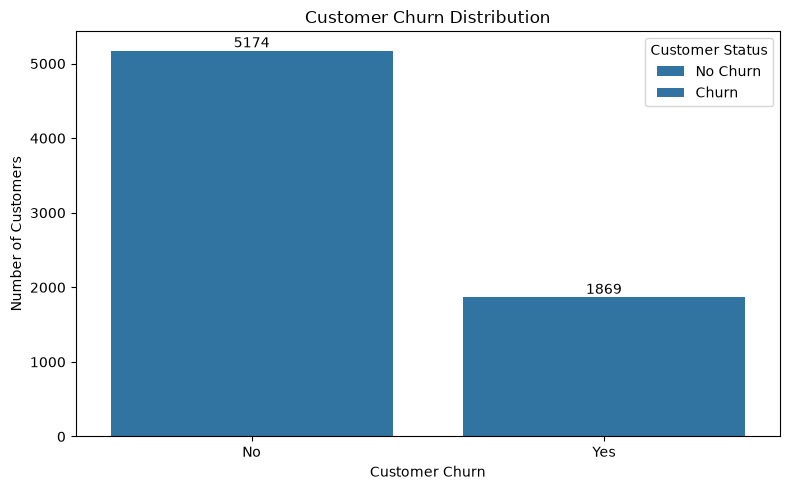

In [35]:
churn_counts = df["Churn"].value_counts().reindex(
    ["No", "Yes"],
    fill_value=0
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "churn_overview" / "churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5 Analyze churn by contract type
### 5.1 Create a contract analysis table

In [10]:
contract_analysis = (
    df.groupby("Contract", observed=True)
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda s: s.eq("Yes").sum()
        )
    )
    .reset_index()
)

contract_analysis["Churn_Rate_Percent"] = (
    contract_analysis["Churned_Customers"]
    / contract_analysis["Total_Customers"]
    * 100
).round(2)

contract_analysis = contract_analysis.sort_values(
    "Churn_Rate_Percent",
    ascending=False
)

display(contract_analysis)

,Contract,Total_Customers,Churned_Customers,Churn_Rate_Percent
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


### 5.2 Visualize churn rate by contract

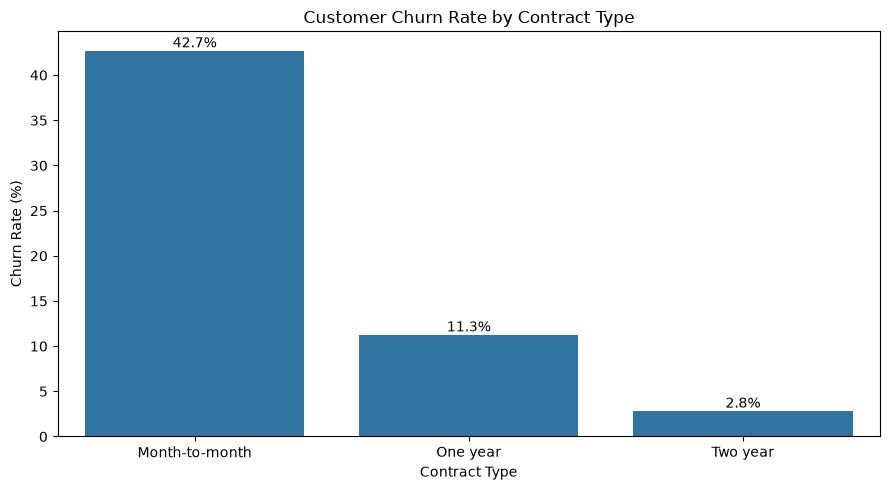

In [11]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=contract_analysis,
    x="Contract",
    y="Churn_Rate_Percent"
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "contract_analysis" / "churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6 Analyze customer tenure
### 6.1 Create tenure groups

In [12]:
tenure_bins = [-1, 12, 24, 36, 48, 72]

tenure_labels = [
    "0-12 Months",
    "13-24 Months",
    "25-36 Months",
    "37-48 Months",
    "49-72 Months"
]

df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

df["Tenure_Group"]

0        0-12 Months
1       25-36 Months
2        0-12 Months
3       37-48 Months
4        0-12 Months
            ...     
7038    13-24 Months
7039    49-72 Months
7040     0-12 Months
7041     0-12 Months
7042    49-72 Months
Name: Tenure_Group, Length: 7043, dtype: category
Categories (5, str): ['0-12 Months' < '13-24 Months' < '25-36 Months' < '37-48 Months' < '49-72 Months']

### 6.2 Calculate churn rates


In [13]:
tenure_analysis = (
    df.groupby("Tenure_Group", observed=False)
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda s: s.eq("Yes").sum()
        )
    )
    .reset_index()
)

tenure_analysis["Churn_Rate_Percent"] = (
    tenure_analysis["Churned_Customers"]
    / tenure_analysis["Total_Customers"]
    * 100
).round(2)

display(tenure_analysis)

,Tenure_Group,Total_Customers,Churned_Customers,Churn_Rate_Percent
0,0-12 Months,2186,1037,47.44
1,13-24 Months,1024,294,28.71
2,25-36 Months,832,180,21.63
3,37-48 Months,762,145,19.03
4,49-72 Months,2239,213,9.51


### 6.3 Visualize the Results

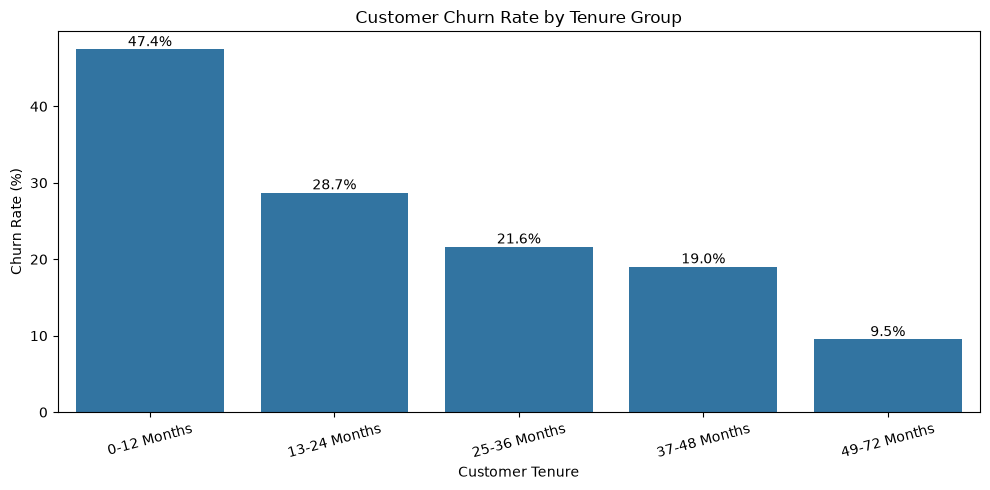

In [14]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=tenure_analysis,
    x="Tenure_Group",
    y="Churn_Rate_Percent"
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "customer_segments" / "churn_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7 Analyze Monthly Charges
### 7.1 Compare charges for churned and retained customers

In [15]:
charges_analysis = (
    df.groupby("Churn", observed=True)
    .agg(
        Customer_Count=("customerID", "count"),
        Average_Monthly_Charges=("MonthlyCharges", "mean"),
        Median_Monthly_Charges=("MonthlyCharges", "median"),
        Average_Tenure=("tenure", "mean")
    )
    .round(2)
)

display(charges_analysis)

,Customer_Count,Average_Monthly_Charges,Median_Monthly_Charges,Average_Tenure
Churn,,,,
No,5174,61.27,64.43,37.57
Yes,1869,74.44,79.65,17.98


### 7.2 Create a Box Plot

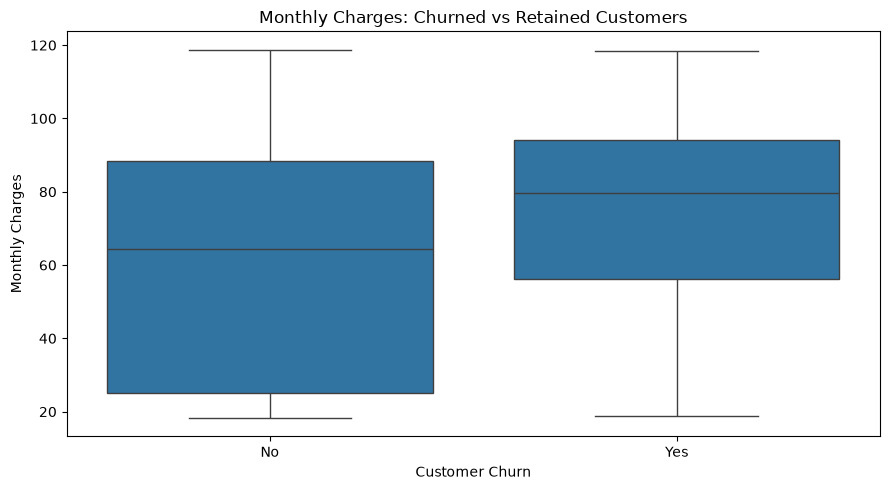

In [17]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges: Churned vs Retained Customers")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "customer_segments" / "monthly_charges_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 8 Analyze Payment Methods

In [18]:
payment_analysis = (
    df.groupby("PaymentMethod", observed=True)
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda s: s.eq("Yes").sum()
        )
    )
    .reset_index()
)

payment_analysis["Churn_Rate_Percent"] = (
    payment_analysis["Churned_Customers"]
    / payment_analysis["Total_Customers"]
    * 100
).round(2)

payment_analysis = payment_analysis.sort_values(
    "Churn_Rate_Percent",
    ascending=False
)

display(payment_analysis)

,PaymentMethod,Total_Customers,Churned_Customers,Churn_Rate_Percent
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24


### 8.1 Visualize Payment-Method Churn

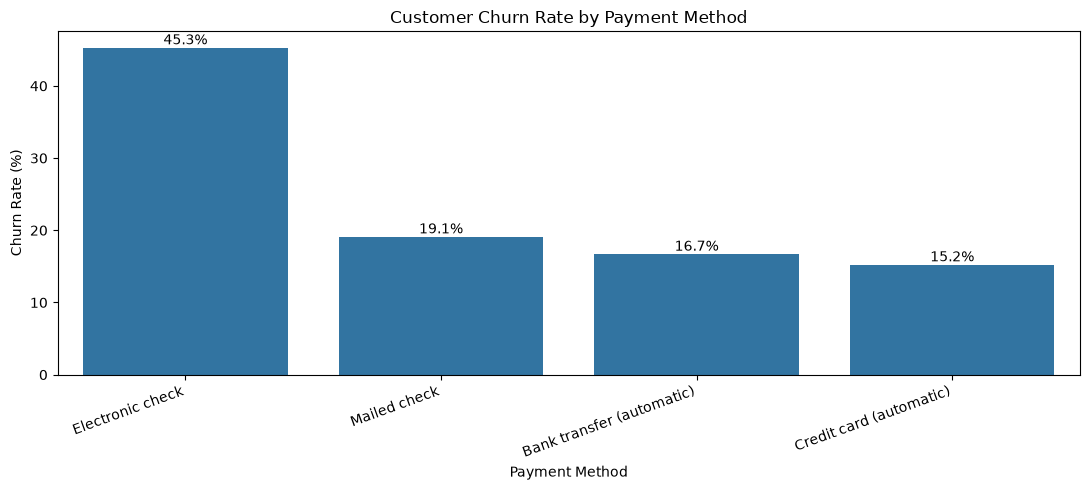

In [20]:
plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=payment_analysis,
    x="PaymentMethod",
    y="Churn_Rate_Percent"
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "service_analysis" / "churn_by_payment_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9 Analyze internet service and support services
### 9.1 Churn by Internet Service

In [21]:
internet_analysis = (
    df.groupby("InternetService", observed=True)
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda s: s.eq("Yes").sum()
        )
    )
    .reset_index()
)

internet_analysis["Churn_Rate_Percent"] = (
    internet_analysis["Churned_Customers"]
    / internet_analysis["Total_Customers"]
    * 100
).round(2)

display(
    internet_analysis.sort_values(
        "Churn_Rate_Percent",
        ascending=False
    )
)

,InternetService,Total_Customers,Churned_Customers,Churn_Rate_Percent
1,Fiber optic,3096,1297,41.89
0,DSL,2421,459,18.96
2,No,1526,113,7.40


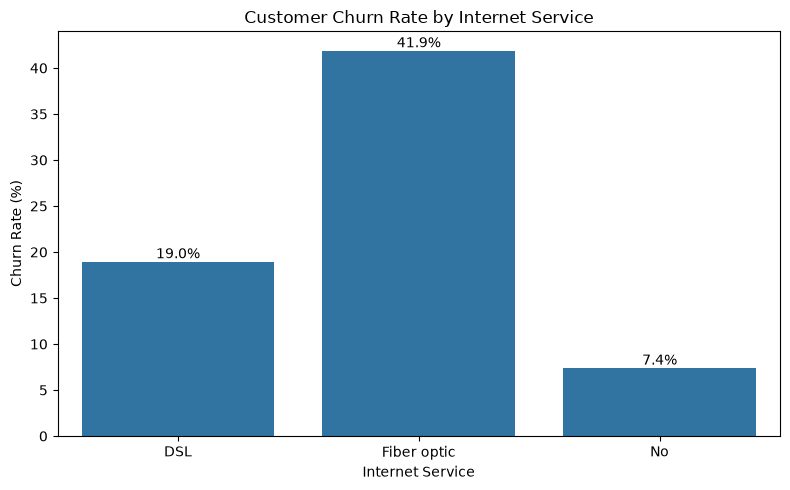

In [22]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=internet_analysis,
    x="InternetService",
    y="Churn_Rate_Percent"
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "service_analysis" / "churn_by_internet_service.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.2 Churn by Technical Support

In [23]:
support_analysis = (
    df.groupby("TechSupport", observed=True)
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda s: s.eq("Yes").sum()
        )
    )
    .reset_index()
)

support_analysis["Churn_Rate_Percent"] = (
    support_analysis["Churned_Customers"]
    / support_analysis["Total_Customers"]
    * 100
).round(2)

display(
    support_analysis.sort_values(
        "Churn_Rate_Percent",
        ascending=False
    )
)

,TechSupport,Total_Customers,Churned_Customers,Churn_Rate_Percent
0,No,3473,1446,41.64
2,Yes,2044,310,15.17
1,No internet service,1526,113,7.40


# 10 Analyze churn by customer demographics

In [24]:
senior_analysis = (
    df.groupby("SeniorCitizen", observed=True)
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda s: s.eq("Yes").sum()
        )
    )
    .reset_index()
)

senior_analysis["Customer_Group"] = (
    senior_analysis["SeniorCitizen"]
    .map({
        0: "Not Senior Citizen",
        1: "Senior Citizen"
    })
)

senior_analysis["Churn_Rate_Percent"] = (
    senior_analysis["Churned_Customers"]
    / senior_analysis["Total_Customers"]
    * 100
).round(2)

display(senior_analysis)

,SeniorCitizen,Total_Customers,Churned_Customers,Customer_Group,Churn_Rate_Percent
0,0,5901,1393,Not Senior Citizen,23.61
1,1,1142,476,Senior Citizen,41.68


In [25]:
gender_analysis = (
    df.groupby("gender", observed=True)
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda s: s.eq("Yes").sum()
        )
    )
    .reset_index()
)

gender_analysis["Churn_Rate_Percent"] = (
    gender_analysis["Churned_Customers"]
    / gender_analysis["Total_Customers"]
    * 100
).round(2)

display(gender_analysis)

,gender,Total_Customers,Churned_Customers,Churn_Rate_Percent
0,Female,3488,939,26.92
1,Male,3555,930,26.16


In [26]:
gender_analysis = (
    df.groupby("gender", observed=True)
    .agg(
        Total_Customers=("customerID", "count"),
        Churned_Customers=(
            "Churn",
            lambda s: s.eq("Yes").sum()
        )
    )
    .reset_index()
)

gender_analysis["Churn_Rate_Percent"] = (
    gender_analysis["Churned_Customers"]
    / gender_analysis["Total_Customers"]
    * 100
).round(2)

display(gender_analysis)

,gender,Total_Customers,Churned_Customers,Churn_Rate_Percent
0,Female,3488,939,26.92
1,Male,3555,930,26.16


# 11 Analyze contract and tenure together

In [28]:
contract_tenure_analysis = pd.pivot_table(
    df,
    index="Tenure_Group",
    columns="Contract",
    values="Churn",
    aggfunc=lambda s: s.eq("Yes").mean() * 100,
    observed=False
).round(2)

display(contract_tenure_analysis)

Contract,Month-to-month,One year,Two year
Tenure_Group,,,
0-12 Months,51.35,10.48,0.00
13-24 Months,37.72,8.12,0.00
25-36 Months,32.51,8.00,2.08
37-48 Months,33.54,13.06,2.25
49-72 Months,26.02,12.93,3.33


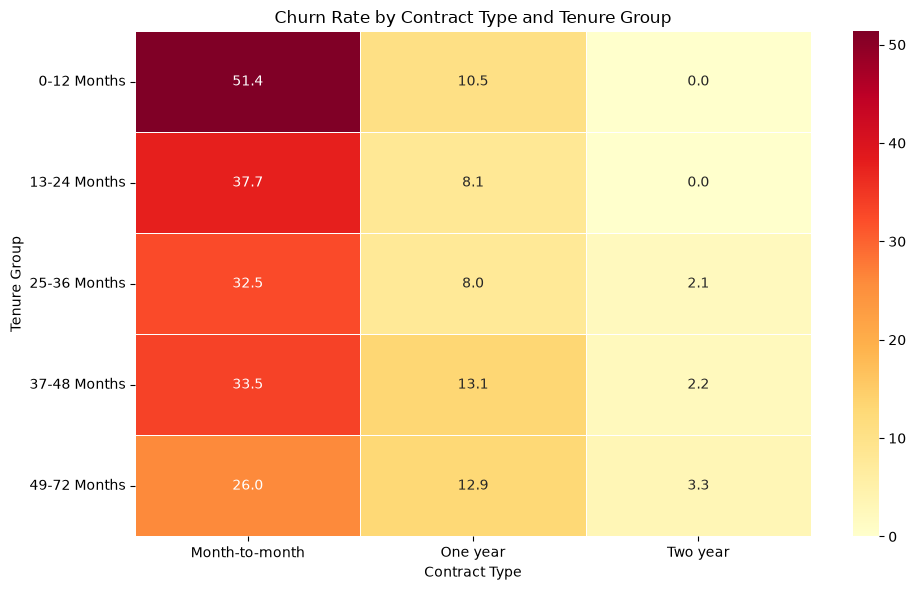

In [29]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    contract_tenure_analysis,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Churn Rate by Contract Type and Tenure Group")
plt.xlabel("Contract Type")
plt.ylabel("Tenure Group")

plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "customer_segments" / "contract_tenure_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 12 Create an EDA Summary Table

In [30]:
summary_tables = {
    "Contract": contract_analysis,
    "Tenure": tenure_analysis,
    "Payment Method": payment_analysis,
    "Internet Service": internet_analysis,
    "Technical Support": support_analysis
}

for analysis_name, analysis_table in summary_tables.items():
    print(f"\n{'=' * 20} {analysis_name} {'=' * 20}")
    display(analysis_table)


==================== Contract ====================


,Contract,Total_Customers,Churned_Customers,Churn_Rate_Percent
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83



==================== Tenure ====================


,Tenure_Group,Total_Customers,Churned_Customers,Churn_Rate_Percent
0,0-12 Months,2186,1037,47.44
1,13-24 Months,1024,294,28.71
2,25-36 Months,832,180,21.63
3,37-48 Months,762,145,19.03
4,49-72 Months,2239,213,9.51



==================== Payment Method ====================


,PaymentMethod,Total_Customers,Churned_Customers,Churn_Rate_Percent
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24



==================== Internet Service ====================


,InternetService,Total_Customers,Churned_Customers,Churn_Rate_Percent
0,DSL,2421,459,18.96
1,Fiber optic,3096,1297,41.89
2,No,1526,113,7.40



==================== Technical Support ====================


,TechSupport,Total_Customers,Churned_Customers,Churn_Rate_Percent
0,No,3473,1446,41.64
1,No internet service,1526,113,7.40
2,Yes,2044,310,15.17


# 13 Save Your EDA Outputs


In [32]:
output_folders = [
    "churn_overview",
    "contract_analysis",
    "customer_segments",
    "service_analysis"
]

for folder in output_folders:
    (OUTPUT_PATH / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Visualization folders are ready.")

Visualization folders are ready.


# Exploratory Data Analysis — Customer Churn

## 1. Project Objective
Explain why customer churn is being analyzed and how
the results can support retention decisions.

## 2. Dataset Overview
- Total customers:
- Total columns:
- Churned customers:
- Retained customers:

## 3. Overall Churn
- Churn rate:
- Retention rate:
- Key observation:

## 4. Contract Analysis
- Highest churn contract:
- Lowest churn contract:
- Key observation:

## 5. Tenure Analysis
- Highest churn tenure group:
- Key observation:

## 6. Monthly Charges
- Average charges for churned customers:
- Average charges for retained customers:
- Key observation:

## 7. Payment Method Analysis
- Highest churn payment method:
- Lowest churn payment method:
- Key observation:

## 8. Service Analysis
- Internet service findings:
- Technical support findings:
- Key observation:

## 9. Customer Demographics
- Senior citizen analysis:
- Gender analysis:
- Dependents analysis:

## 10. Combined Analysis
- Contract and tenure findings:
- Relevant customer segments:

## 11. Business Recommendations
Provide evidence-based recommendations
based on the actual findings.

## 12. Limitations
- Observational analysis does not establish causality.
- Historical churn patterns do not guarantee future behavior.
- Missing values and data limitations must be documented.

## 13. Conclusion
Summarize the most important findings.

In [1]:
import pandas as pd

file_path = r"C:\Portfolio Projects\Customer Churn Analysis\data\cleaned\telco_churn_cleaned.csv"

df = pd.read_csv(file_path)

print("SeniorCitizen data type:")
print(df["SeniorCitizen"].dtype)

print("\nUnique values:")
print(df["SeniorCitizen"].unique())

print("\nValue counts:")
print(df["SeniorCitizen"].value_counts(dropna=False))

SeniorCitizen data type:
int64

Unique values:
[0 1]

Value counts:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
